# Budget Allocation Auction: VCG vs simpler allocation rules

**Simulation.** Units hold private information about the value of extra funding. The VCG (Clarke pivot) mechanism is compared with three simpler rules: proportional-to-report, first-price and uniform-price. The notebook is anchored on the structure of a synthetic finance dataset.

## Problem

A fixed budget of $B$ money units is to be allocated among cost centers. Each cost center (here, a *unit* after replication) knows privately how much value it would extract from one more money unit, and that value falls as more money is received. A planner who asks units to report their values faces two problems: units may misreport to get more money (incentives), and the planner wants the money to go where it creates the most value (efficiency).

Questions:
1. Does VCG allocate efficiently when everyone is truthful, and how efficient are the other rules under inflated or best-response reports?
2. Is truthful reporting a dominant strategy under each mechanism (2000 random unit-misreport pairs)?
3. What do VCG payments raise, and is the mechanism individually rational and budget-balanced?
4. How do the number of units and the budget size affect efficiency?

## Data

**Real structure from the synthetic demo data.** The file `Cashi RAG/aggs/_consolidado.parquet` was created by `seed_demo_data.py` (`source: synthetic-demo`). It is **not** real company data. From it I use only:
- the 6 cost centers (`ID_CENTRO_COSTOS`) and their directions,
- each center's totals for weeks 1 to 43: $P26$ (plan 2026), $R26$ (actual 2026) and their ratio $R26/P26$,
- the overspend money $R26-P26$, which sets the relative scale of each center.

**Simulated valuations.** Everything about how the units value money is simulated: the marginal value curves, the noise that replicates each center into 40 units, the decay parameters, and every report and misreport. The data does not contain any values of money, so none of the valuation numbers below describe real cost centers.

**Observed finding.** The overspend ratio $R26/P26$ is exactly 1.03 for all six centers, so the data carries no cross-center difference in ratio. The centers differ only in overspend money (about 0.96 to 1.04 of the mean). The decay rule below therefore gives every center the same decay.

## Method

**Generative model.** Let $c$ index a center and $i$ a replicated unit.

$$m_c=\frac{\text{overspend}_c}{\overline{\text{overspend}}},\qquad z_c=\frac{r_c-\min r}{\max r-\min r}\ (z_c=0.5 \text{ if the range is }0),\qquad d_c=0.6+0.3\,z_c$$

$$m_i=m_c\,e^{\varepsilon_i},\ \varepsilon_i\sim\mathcal N(0,0.3^2);\qquad d_i=\mathrm{clip}(d_c+\eta_i,\,0.5,\,0.97),\ \eta_i\sim\mathcal N(0,0.02^2)$$

Each unit has $N=6\times 40=240$ units by default. Seed $=2026$.

**Valuation and budget.** Slot $k$ is worth $v_i(k)=m_i d_i^{\,k-1}$ for $k=1,\dots,K=30$. The total value of $k$ slots is $V_i(k)=\sum_{j\le k}v_i(j)$, which is concave. The budget has $B$ slots (one slot = one money unit).

**Mechanisms.** A unit reports a curve $(\hat m_i,\hat d_i)$. Let $\hat v_i(k)$ be the reported slot values.

- **VCG (Clarke pivot).** Allocate the $B$ highest reported slot values. Because the values are concave, this greedy allocation is optimal. The payment is
$$p_i=W_{-i}-\Big(W-\textstyle\sum_{k\le x_i}\hat v_i(k)\Big),$$
where $W$ is the maximal reported welfare and $W_{-i}$ is the maximal welfare of the other units when $i$ is removed. $W_{-i}$ is computed by re-solving without $i$.
- **Proportional.** Split $B$ slots in proportion to $\sum_{k=1}^{K}\hat v_i(k)$, with largest-remainder rounding and a cap of $K$. No payment.
- **First-price.** The VCG allocation, and winners pay their reported value of the slots won.
- **Uniform price.** The VCG allocation, and every won slot pays the highest losing bid, $\hat v_{(B+1)}$.

Utility is $u_i=V_i(x_i)-p_i$, where $V_i$ uses the **true** curve.

**Efficiency** is total true value of the allocation divided by the optimum (the $B$ highest true slot values).

**Truthfulness test.** For 2000 random pairs (unit $i$, misreport $(f\,m_i,\ g\,d_i)$ with $f\sim U[0.5,2]$, $g\sim U[0.7,1.3]$), with all others truthful, the gain is $u_i(\text{misreport})-u_i(\text{truth})$. A violation is a gain above $10^{-9}$.

**Best response.** Grid search over $f\in\{0.5,\dots,2.0\}$ and $g\in\{0.8,\dots,1.2\}$ against truthful others, followed by one simultaneous round of the best responses.

In [1]:
import sys
sys.path.insert(0, '.')
sys.path.insert(0, '..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import budget_auction as ba

pd.set_option('display.width', 180)
pd.set_option('display.float_format', lambda x: f'{x:,.6f}')
print('Module:', ba.__file__)
print('Data path:', ba.DATA_PATH, ba.DATA_PATH.exists())
params = ba.center_parameters()
print(params.to_string())
print('Overspend ratio range across centers:', params['overspend_ratio'].min(), params['overspend_ratio'].max())

Module: <repo>/Budget Allocation Auction\budget_auction.py
Data path: <repo>/Cashi RAG\aggs\_consolidado.parquet True
                               P26               R26  overspend_ratio  overspend_money      m_c      d_c         direccion
ID_CENTRO_COSTOS                                                                                                          
FLE-005          16,383,817.000000 16,875,331.510000         1.030000   491,514.510000 0.963722 0.750000     Direccion Sur
LUZ-003          17,716,817.000000 18,248,321.510000         1.030000   531,504.510000 1.042131 0.750000  Direccion Centro
MTO-004          17,717,634.000000 18,249,163.020000         1.030000   531,529.020000 1.042180 0.750000  Direccion Centro
NOM-001          16,899,817.000000 17,406,811.510000         1.030000   506,994.510000 0.994074 0.750000   Direccion Norte
PUB-006          16,384,634.000000 16,876,173.020000         1.030000   491,539.020000 0.963770 0.750000     Direccion Sur
REN-002          16,9

N units = 240, K = 30, B = 480, total slots = 7200
true m range [0.313, 2.682], true d range [0.6920, 0.8093]
optimum (true value of best B slots): 479.8939


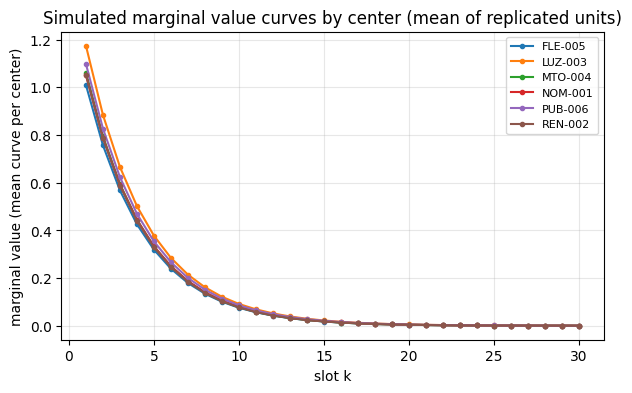

In [2]:
mk = ba.generate_market(units_per_center=40)
B = 2 * mk.n            # default budget: 2 slots per unit on average (N=240 -> B=480)
print(f'N units = {mk.n}, K = {mk.K}, B = {B}, total slots = {mk.n*mk.K}')
print(f'true m range [{mk.m.min():.3f}, {mk.m.max():.3f}], true d range [{mk.d.min():.4f}, {mk.d.max():.4f}]')
print('optimum (true value of best B slots):', round(mk.opt(B), 4))

fig, ax = plt.subplots(figsize=(7, 4))
k = np.arange(1, mk.K + 1)
for c, name in enumerate(mk.center_names):
    idx = mk.center == c
    ax.plot(k, mk.m[idx].mean() * mk.d[idx].mean() ** (k - 1), marker='o', ms=3, label=name)
ax.set_xlabel('slot k'); ax.set_ylabel('marginal value (mean curve per center)')
ax.set_title('Simulated marginal value curves by center (mean of replicated units)')
ax.legend(fontsize=8); ax.grid(alpha=.3); plt.show()

In [3]:
print('=== Truthful profile: revenue, efficiency, participation ===')
rev = ba.revenue_table(mk, B)
print(rev.to_string())
print()
print('=== Individual rationality (truthful reports) ===')
ir = ba.individual_rationality(mk, B)
print(ir.to_string())

=== Truthful profile: revenue, efficiency, participation ===
              slots_allocated  units_winning  total_true_value  efficiency    revenue  revenue_pct_budget  revenue_pct_value
VCG                480.000000     221.000000        479.893876    1.000000 318.501439            0.663545           0.663691
Proportional       480.000000     240.000000        475.128658    0.990070   0.000000            0.000000           0.000000
FirstPrice         480.000000     221.000000        479.893876    1.000000 479.893876            0.999779           1.000000
Uniform            480.000000     221.000000        479.893876    1.000000 318.779433            0.664124           0.664271

=== Individual rationality (truthful reports) ===
              min_utility  units_negative_utility
VCG              0.000000                0.000000
Proportional     0.313133                0.000000
FirstPrice       0.000000                0.000000
Uniform          0.000000                0.000000


In [4]:
print('=== Efficiency under scenarios (true value / optimum) ===')
scen = ba.efficiency_under_scenarios(mk, B, reps=20)
print(scen.to_string())
print('Inflation draws: 20 reps of f_i ~ U[1,2] per unit, mean and sd (ddof=1) shown.')

=== Efficiency under scenarios (true value / optimum) ===


              eff_truthful  eff_inflate_U12_mean  eff_inflate_U12_sd  eff_best_response  units_with_profitable_deviation  mean_br_gain
VCG               1.000000              0.977986            0.001646           1.000000                         0.000000      0.000000
Proportional      0.990070              0.981147            0.001459           0.985796                       240.000000      2.049654
FirstPrice        1.000000              0.978193            0.001655           0.979550                       206.000000      0.505670
Uniform           1.000000              0.977824            0.002386           0.999998                         2.000000      0.000003
Inflation draws: 20 reps of f_i ~ U[1,2] per unit, mean and sd (ddof=1) shown.


=== Truthfulness test: 2000 random (unit, misreport) pairs ===


             pairs violations violation_rate max_gain max_gain_if_any_violation mean_gain_of_violations
VCG           2000          0       0.000000 0.000000                  0.000000                0.000000
Proportional  2000       1001       0.500500 3.309039                  3.309039                1.259617
FirstPrice    2000        378       0.189000 1.815396                  1.815396                0.391461
Uniform       2000          2       0.001000 0.000605                  0.000605                0.000361
VCG: violations = 0 | raw max gain = 1.1368683772161603e-13


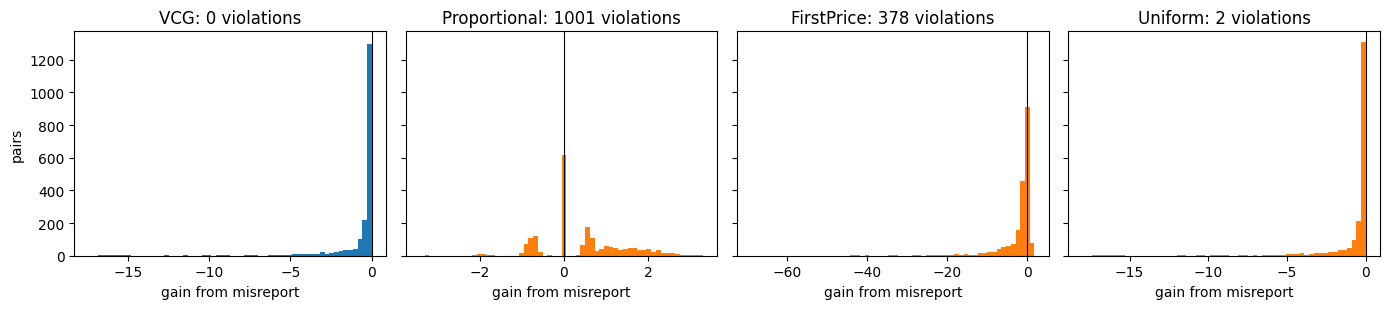

In [5]:
print('=== Truthfulness test: 2000 random (unit, misreport) pairs ===')
tt = ba.truthfulness_test(mk, B, n_pairs=2000)
summary = tt.drop(columns='gains')
print(summary.to_string())
vcg_gains = tt.loc['VCG', 'gains']
print('VCG: violations =', int(tt.loc['VCG', 'violations']), '| raw max gain =', float(vcg_gains.max()))
assert int(tt.loc['VCG', 'violations']) == 0, 'VCG truthfulness violated - investigate'

fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), sharey=True)
for a, mech in zip(axes, ba.MECHANISMS):
    g = tt.loc[mech, 'gains'].astype(float)
    a.hist(g, bins=60, color='tab:blue' if mech == 'VCG' else 'tab:orange')
    a.axvline(0, color='k', lw=.8)
    a.set_title(f'{mech}: {int(tt.loc[mech, "violations"])} violations')
    a.set_xlabel('gain from misreport')
axes[0].set_ylabel('pairs')
plt.tight_layout(); plt.show()

=== Efficiency vs number of units (B = 2N) and vs budget (N = 240) ===


 units_per_center   N   B    mechanism  eff_truthful  eff_inflate_mean
                4  24  48          VCG      1.000000          0.972400
                4  24  48 Proportional      0.990700          0.985600
                4  24  48   FirstPrice      1.000000          0.972400
                4  24  48      Uniform      1.000000          0.972400
               10  60 120          VCG      1.000000          0.977400
               10  60 120 Proportional      0.993600          0.983700
               10  60 120   FirstPrice      1.000000          0.977400
               10  60 120      Uniform      1.000000          0.977400
               20 120 240          VCG      1.000000          0.979100
               20 120 240 Proportional      0.992000          0.982400
               20 120 240   FirstPrice      1.000000          0.979100
               20 120 240      Uniform      1.000000          0.979100
               40 240 480          VCG      1.000000          0.978700
      

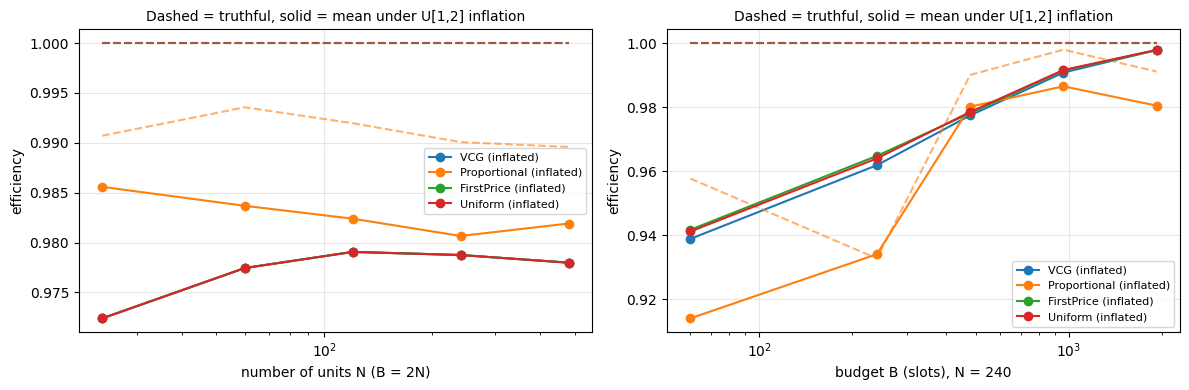

In [6]:
print('=== Efficiency vs number of units (B = 2N) and vs budget (N = 240) ===')
res_n, res_b = ba.sweep()
print(res_n.round(4).to_string(index=False))
print()
print(res_b.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for mech in ba.MECHANISMS:
    s = res_n[res_n.mechanism == mech]
    line, = axes[0].plot(s['N'], s['eff_inflate_mean'], marker='o', label=f'{mech} (inflated)')
    axes[0].plot(s['N'], s['eff_truthful'], ls='--', color=line.get_color(), alpha=.6)
    s = res_b[res_b.mechanism == mech]
    line, = axes[1].plot(s['B'], s['eff_inflate_mean'], marker='o', label=f'{mech} (inflated)')
    axes[1].plot(s['B'], s['eff_truthful'], ls='--', color=line.get_color(), alpha=.6)
axes[0].set_xscale('log'); axes[0].set_xlabel('number of units N (B = 2N)'); axes[0].set_ylabel('efficiency')
axes[1].set_xscale('log'); axes[1].set_xlabel('budget B (slots), N = 240'); axes[1].set_ylabel('efficiency')
axes[0].set_title('Dashed = truthful, solid = mean under U[1,2] inflation', fontsize=10)
axes[1].set_title('Dashed = truthful, solid = mean under U[1,2] inflation', fontsize=10)
for a in axes: a.grid(alpha=.3); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

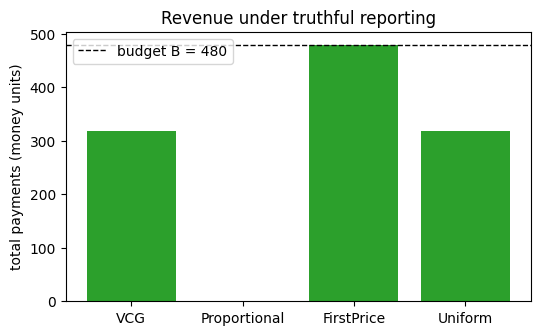

VCG revenue as share of budget: 0.6635


In [7]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(rev.index, rev['revenue'].astype(float), color='tab:green')
ax.axhline(B, color='k', ls='--', lw=1, label=f'budget B = {B}')
ax.set_ylabel('total payments (money units)'); ax.set_title('Revenue under truthful reporting')
ax.legend(); plt.show()
print('VCG revenue as share of budget:', round(float(rev.loc['VCG', 'revenue_pct_budget']), 4))

## Results

Setup: N = 240 units (6 centers x 40), K = 30 slots, B = 480 slots by default, seed 2026. All numbers are the values printed by the cells above.

**Truthfulness (2000 random unit-misreport pairs, others truthful).**
- VCG: 0 violations. Raw max gain 1.1e-13, which is floating-point noise.
- Uniform price: 2 violations (0.1%), max gain 0.0006.
- First price: 378 violations (18.9%), max gain 1.82.
- Proportional: 1001 violations (50.1%), max gain 3.31.

**Efficiency (true value / optimum).**
- Truthful reports: VCG, first price and uniform price all reach 1.0000. Proportional reaches 0.9901.
- Random inflation f_i ~ U[1,2] (20 draws, mean +/- sd): VCG 0.9780 +/- 0.0016, first price 0.9782 +/- 0.0017, uniform 0.9778 +/- 0.0024, proportional 0.9811 +/- 0.0015. Inflation hurts VCG too, because VCG is truthful only in the sense of incentives, not robust to arbitrary inflation.
- Best response (one simultaneous round against truthful others): VCG best response is truth for all 240 units (0 profitable deviations), efficiency 1.0000. First price: 206 units deviate profitably, efficiency 0.9796. Proportional: all 240 units deviate, mean gain 2.05, efficiency 0.9858. Uniform: 2 units deviate, efficiency 1.0000.

**Payments and budget (truthful reports, budget = 480 money units).**
- VCG revenue = 318.50, which is 66.4% of the budget and 66.4% of the total true value allocated. Uniform price raises 318.78 (66.4%). First price raises all 479.89. Proportional raises 0.
- So VCG is not budget-balanced: units pay about two thirds of the value they receive, and the planner keeps the surplus unless it rebates it. Rebating it would need a separate design, which this project does not test.

**Individual rationality (truthful reports).** Minimum utility is 0 for VCG, first price and uniform, and 0.31 for proportional. No unit has negative utility under any mechanism.

**Number of units (B = 2N).** VCG is 1.0000 under truthful reports for N = 24 to 480. Under inflation it stays within 0.972 to 0.979 with no clear trend in N.

**Budget size (N = 240).** Under inflation, VCG efficiency rises from 0.939 (B = 60) to 0.998 (B = 1920). Proportional truthful efficiency is not monotone: 0.958 at B = 60, 0.933 at B = 240, 0.990 at B = 480, 0.998 at B = 960, 0.991 at B = 1920. The cause of the dip at B = 240 was not investigated.

**Caveats.**
- The valuations and the replication noise are simulated. The only data-derived inputs are the overspend money (relative scale m_c, from 0.96 to 1.04) and the overspend ratio.
- The overspend ratio is exactly 1.03 for every center, so the decay rule gives d_c = 0.75 everywhere. The results do not depend on the real ratio.
- Truthfulness is checked on 2000 sampled pairs with a two-parameter misreport family (scale and decay). This supports the theory but does not prove it.
- The efficiency gaps are small (at most about 2 percent under inflation) because the market is homogeneous in decay.
- Inflation and sweep results use 10 to 20 random draws on one market seed.


## Conclusions
1. **VCG makes honesty the best policy; the alternatives do not.** In 2,000 random (unit, misreport) tests, no unit ever gained by lying under VCG (the largest "gain" is 1e-13, floating-point noise). Lying paid off in 50.1% of tests under proportional allocation (gain up to 3.31), 18.9% under first-price (up to 1.82) and 0.1% under uniform price (up to 0.0006). Under a best-response search, VCG's best response is truth for all 240 units, while 206 units deviate profitably under first-price and all 240 under proportional allocation.
2. **Truthful play makes three mechanisms efficient, but only VCG stays truthful.** With honest reports VCG, first-price and uniform price allocate the budget optimally (efficiency 1.000); proportional allocation reaches 0.990. The point of VCG is not a higher number under honest reports but that honest reports are rational, so the planner can believe them.
3. **Efficiency losses from strategic reporting are small in this market.** With random inflation of reports by a factor between 1 and 2, VCG, first-price and uniform price all fall to about 0.978 and proportional to 0.981; under best responses first-price reaches 0.980 and proportional 0.986. The gaps are small because the simulated market is homogeneous in decay (all units have a marginal-value decay of about 0.75), so misreporting rarely changes who gets the budget. This is a limitation of the data, not a general result.
4. **VCG is not free.** The units pay 318.5 money units, 66.4% of the budget, and the planner keeps that surplus; no rebate design that restores budget balance without breaking incentives was tested. In an internal budget process that money would have to be returned or the "payment" would have to be an accounting charge. No truthful unit has negative utility under any mechanism, so participation is voluntary.
5. **What is real and what is simulated.** The structure (six cost centers, three divisions, overspend money) comes from the synthetic Cashi demo data; the valuations and the 240 replicated units are simulated. The overspend ratio is exactly 1.03 for every center in that data, so it carries no cross-center signal and the results do not depend on it.
6. **Limits.** Truthfulness is tested by sampling 2,000 pairs with one family of misreports (scale and decay), which supports but does not prove the theory; inflation and sweeps use 10 to 20 draws from one market seed; one result (proportional efficiency not monotone in the budget) was not investigated.

**Takeaway for the interview:** VCG charges each winner the harm they cause others, so the best strategy is to report your true value; the price is a payment rule that is not budget-balanced. The honest framing of this project is a mechanism-design simulation anchored on a finance data structure, not an evaluation on real budgets.